# Week 7 - Day 2

# Image Classification with CNNs: A Bigger, More Realistic Task

## A Beginner-Friendly, Fully Explained Walkthrough

Yesterday's digits were small (8x8), grayscale, and always neatly centred - genuinely one of the easiest image tasks there is. That's exactly why our CNN and ANN tied at about 97.5% accuracy: the task was too easy to show off a CNN's real strength.

Today we build a **bigger, more colourful, more realistic** image dataset ourselves - shapes that can appear **anywhere** in the image, at **any size**, at **any rotation**, on **noisy, coloured backgrounds**. This is deliberately closer to a real-world photo, where the thing you're trying to recognise is never guaranteed to sit neatly in the centre of the frame.

We will not rush. Every new code cell is followed by a plain-English, line-by-line explanation.

## Learning Objectives

By the end of this lesson, you will be able to:

- Explain why a harder, more realistic image dataset should widen the gap between an ANN and a CNN.
- Build a synthetic image dataset with OpenCV, understanding every drawing/randomisation step.
- Prepare a colour (RGB) image dataset for training - normalizing, splitting, and shaping it correctly.
- Train an ANN baseline on this harder task and observe its limitations.
- Build and train a deeper CNN (multiple Conv+Pool blocks) suited to a more complex task.
- Compare the ANN and CNN fairly, using real results rather than assumptions.
- Explain what data augmentation is, and implement it using Keras's built-in augmentation layers.
- Evaluate whether data augmentation actually improved this specific model.

## Why This Lesson Matters

Think about a real security camera at the gate of an estate, trying to recognise objects or vehicles. A car in the photo will never always be perfectly centred, always the same size, or always facing the same direction. It could be closer to the camera, further away, tilted, partly in shadow, on a rainy day or a sunny one.

Yesterday's digits were nothing like that - every digit sat neatly centred in its own tiny 8x8 box. Today's shapes dataset is our first step toward something more honest: shapes placed at **random positions**, **random sizes**, **random rotations**, on **randomly coloured, noisy backgrounds** - much closer to what a CNN actually needs to handle in the real world.

## Recap: Week 7 Day 1 -> Today

| | Week 7 Day 1 (Digits) | Today (Shapes) |
|---|---|---|
| Image size | 8x8 | 32x32 - 16x more pixels |
| Colour | Grayscale (1 channel) | Full colour (3 channels: Red, Green, Blue) |
| Position of the subject | Always centred | Random position anywhere in the frame |
| Rotation/size | Fixed | Random rotation and random size |
| Background | Plain black | Random colour, with pixel noise |
| Classes | 10 digits | 5 shapes (circle, square, triangle, star, cross) |

Everything else - `Conv2D`, `MaxPooling2D`, `Flatten`, `Dense`, `softmax`, `sparse_categorical_crossentropy` - is exactly what you already learned yesterday. Today just turns up the difficulty.

# Part 1 - Building a Bigger, More Realistic Dataset

There's no ready-made "colourful shapes at random positions" dataset built into scikit-learn, so we'll build one ourselves using OpenCV - the same library we used for Sobel edge detection yesterday.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

CLASSES = ["circle", "square", "triangle", "star", "cross"]
CANVAS_SIZE = 32   # our final image will be 32x32 pixels
PATCH_SIZE = 18    # the shape itself is drawn inside an 18x18 patch first

print("Classes:", CLASSES)
print("Final image size:", CANVAS_SIZE, "x", CANVAS_SIZE)

Classes: ['circle', 'square', 'triangle', 'star', 'cross']
Final image size: 32 x 32


### Line-by-Line Breakdown

- **`import cv2`** - OpenCV, the same image-drawing and image-processing library from yesterday's Sobel example.
- **`CLASSES = [...]`** - A plain Python list naming our 5 shape categories. The *position* of each name in this list will later become its numeric label (`circle` = 0, `square` = 1, and so on) - the same idea as digit labels `0`-`9` yesterday, just for shapes instead.
- **`CANVAS_SIZE = 32`** - Our whole image will be 32 pixels by 32 pixels - 16 times more pixels than yesterday's tiny 8x8 grid.
- **`PATCH_SIZE = 18`** - We'll first draw each shape onto a smaller 18x18 square (a "patch"), then paste that patch onto the bigger 32x32 canvas at a random position. Drawing on a smaller patch first makes it much easier to rotate and resize the shape cleanly before placing it.

## Step 1 - A Function That Draws One Shape

We'll write one function that knows how to draw any of our 5 shapes onto a small patch, given a colour.

In [2]:
def draw_shape_patch(shape, color):
    patch = np.zeros((PATCH_SIZE, PATCH_SIZE, 3), dtype=np.uint8)
    c = PATCH_SIZE // 2

    if shape == "circle":
        cv2.circle(patch, (c, c), c - 2, color, -1)

    elif shape == "square":
        cv2.rectangle(patch, (2, 2), (PATCH_SIZE - 3, PATCH_SIZE - 3), color, -1)

    elif shape == "triangle":
        pts = np.array([[c, 1], [1, PATCH_SIZE - 2], [PATCH_SIZE - 2, PATCH_SIZE - 2]], np.int32)
        cv2.fillPoly(patch, [pts], color)

    elif shape == "star":
        outer_radius = c - 1
        inner_radius = outer_radius * 0.45
        points = []
        for i in range(10):
            angle = i * np.pi / 5 - np.pi / 2
            radius = outer_radius if i % 2 == 0 else inner_radius
            x = int(c + radius * np.cos(angle))
            y = int(c + radius * np.sin(angle))
            points.append([x, y])
        pts = np.array(points, np.int32)
        cv2.fillPoly(patch, [pts], color)

    elif shape == "cross":
        thickness = PATCH_SIZE // 4
        cv2.rectangle(patch, (c - thickness // 2, 1), (c + thickness // 2, PATCH_SIZE - 2), color, -1)
        cv2.rectangle(patch, (1, c - thickness // 2), (PATCH_SIZE - 2, c + thickness // 2), color, -1)

    return patch

### Line-by-Line Breakdown

- **`def draw_shape_patch(shape, color):`** - Our function takes which shape to draw (a text string like `"circle"`) and what colour to use (an `(R, G, B)` number triple).
- **`patch = np.zeros((PATCH_SIZE, PATCH_SIZE, 3), dtype=np.uint8)`** - Creates a blank 18x18 patch with **3** channels (Red, Green, Blue) instead of the single grayscale channel we used for digits - this is our first *colour* image in the course. Every pixel starts at `(0, 0, 0)`, which is black.
- **`c = PATCH_SIZE // 2`** - The centre point of the patch (`9`, since `18 // 2 = 9`), which we'll reuse for every shape.
- **`if shape == "circle": cv2.circle(patch, (c, c), c - 2, color, -1)`** - Draws a filled circle centred at `(c, c)`, with a radius of `c - 2` (slightly smaller than the patch, so it doesn't get clipped at the edges), filled solid (`-1` thickness, same trick as Day 1).
- **`elif shape == "square": cv2.rectangle(...)`** - Draws a filled square using two corner points, `(2, 2)` and `(PATCH_SIZE - 3, PATCH_SIZE - 3)`, leaving a small margin from the patch edge.
- **`elif shape == "triangle":`** - We manually list 3 corner points (`pts`) - top-middle, bottom-left, bottom-right - and use **`cv2.fillPoly(patch, [pts], color)`** to fill in the triangle those 3 points describe. `fillPoly` can fill *any* shape described by a list of corner points, not just triangles.
- **`elif shape == "star":`** - A 5-pointed star needs **10** points alternating between an outer radius (the star's tips) and an inner radius (the star's inner corners). The `for i in range(10):` loop walks around a circle in 10 equal angle steps, alternating between `outer_radius` and `inner_radius` using `i % 2 == 0` (True on even steps, False on odd steps), calculating each point's `(x, y)` position with basic trigonometry (`cos` for the horizontal position, `sin` for the vertical position). We then fill in all 10 points with `fillPoly`, exactly like the triangle.
- **`elif shape == "cross":`** - Draws two overlapping rectangles - one tall and thin, one wide and thin - which together form a plus/cross shape.
- **`return patch`** - Hands back the finished 18x18 colour patch containing just that one shape.

## Step 2 - Helper for Random Colours

In [3]:
def random_color(rng):
    return tuple(int(x) for x in rng.integers(80, 256, size=3))

### Line-by-Line Breakdown

- **`rng.integers(80, 256, size=3)`** - Generates 3 random whole numbers, each between 80 and 255, representing Red, Green, and Blue brightness values. We start at `80` rather than `0` to avoid overly dark, hard-to-see colours.
- **`tuple(int(x) for x in ...)`** - OpenCV expects plain Python numbers (not NumPy's own number types) inside a `tuple` like `(R, G, B)`, so we convert each value explicitly.
- **`rng`** - Notice this function takes a random number generator as an input, rather than creating its own. We'll create **one** `rng` for our whole dataset, so that every image in the notebook is reproducible if you re-run it from the top.

## Step 3 - Assembling One Full, Randomised Image

This is where everything comes together: pick a random background, draw the shape, rotate and resize it, then paste it at a random position.

In [4]:
def make_image(shape, rng):
    # 1. Random background colour, with a little pixel noise for realism
    bg_color = random_color(rng)
    img = np.full((CANVAS_SIZE, CANVAS_SIZE, 3), bg_color, dtype=np.uint8)
    noise = rng.normal(0, 8, img.shape)
    img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    # 2. Pick a shape colour that stands out clearly from the background
    shape_color = random_color(rng)
    while np.linalg.norm(np.array(shape_color) - np.array(bg_color)) < 80:
        shape_color = random_color(rng)

    # 3. Draw the shape on its own small patch
    patch = draw_shape_patch(shape, shape_color)

    # 4. Randomly rotate and resize that patch
    angle = rng.uniform(0, 360)
    scale = rng.uniform(0.8, 1.3)
    rotation_matrix = cv2.getRotationMatrix2D((PATCH_SIZE / 2, PATCH_SIZE / 2), angle, scale)
    rotated_patch = cv2.warpAffine(patch, rotation_matrix, (PATCH_SIZE, PATCH_SIZE))
    shape_mask = cv2.cvtColor(rotated_patch, cv2.COLOR_BGR2GRAY) > 5

    # 5. Paste the rotated shape onto the background at a RANDOM position
    max_offset = CANVAS_SIZE - PATCH_SIZE
    offset_x = rng.integers(0, max_offset)
    offset_y = rng.integers(0, max_offset)

    region = img[offset_y:offset_y + PATCH_SIZE, offset_x:offset_x + PATCH_SIZE]
    region[shape_mask] = rotated_patch[shape_mask]
    img[offset_y:offset_y + PATCH_SIZE, offset_x:offset_x + PATCH_SIZE] = region

    # 6. A touch of blur, since real-world photos are never perfectly sharp
    img = cv2.GaussianBlur(img, (3, 3), 0.4)

    return img

### Line-by-Line Breakdown

**Step 1 - Background:**
- **`img = np.full((CANVAS_SIZE, CANVAS_SIZE, 3), bg_color, dtype=np.uint8)`** - `np.full` creates a grid already filled with a given value - here, a full 32x32x3 canvas, every pixel set to our random background colour.
- **`noise = rng.normal(0, 8, img.shape)`** - Generates random "static," drawn from a normal (bell-curve) distribution centred at 0, with a spread of 8. This is added on top of the flat background colour so it isn't perfectly uniform - real photographed surfaces never are.
- **`np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)`** - We convert to decimal numbers to safely add the noise (since `uint8` can't hold negative numbers or values above 255), add the noise, then `clip` forces every value back into the valid 0-255 brightness range, and we convert back to `uint8` for OpenCV/matplotlib to display correctly.

**Step 2 - Shape colour:**
- **`while np.linalg.norm(...) < 80: shape_color = random_color(rng)`** - `np.linalg.norm(a - b)` measures how "far apart" two colours are (treating R, G, B as 3 coordinates). This loop keeps picking new random shape colours **until** it finds one sufficiently different from the background - otherwise we might occasionally generate a shape that's nearly invisible against its own background!

**Step 3-4 - Rotate and resize:**
- **`patch = draw_shape_patch(shape, shape_color)`** - Uses our Step 1 function to draw the shape at its default size and orientation.
- **`cv2.getRotationMatrix2D((PATCH_SIZE/2, PATCH_SIZE/2), angle, scale)`** - Builds a mathematical "recipe" (a rotation matrix) for rotating around the patch's centre by a random `angle` (0-360 degrees) and resizing by a random `scale` (80%-130% of the original size).
- **`cv2.warpAffine(patch, rotation_matrix, (PATCH_SIZE, PATCH_SIZE))`** - Actually *applies* that rotation-and-scale recipe to the patch, producing `rotated_patch`.
- **`shape_mask = cv2.cvtColor(rotated_patch, cv2.COLOR_BGR2GRAY) > 5`** - Converts the rotated patch to grayscale, then checks which pixels are brighter than `5` (i.e. "not part of the black background of the patch itself"). This gives us a `True`/`False` map marking exactly which pixels belong to the shape, so we can paste *only* those pixels, not the small patch's own black corners.

**Step 5 - Random position:**
- **`max_offset = CANVAS_SIZE - PATCH_SIZE`** - The furthest right/down we can place the patch without it running off the edge of the 32x32 canvas.
- **`offset_x = rng.integers(0, max_offset)`** and **`offset_y = ...`** - Randomly choose exactly where (top-left corner) to place the shape this time - this is the single most important line in the whole function, since it's what makes the shape's position genuinely unpredictable, unlike yesterday's always-centred digits.
- **`region[shape_mask] = rotated_patch[shape_mask]`** - Copies over *only* the shape's actual pixels (using our `shape_mask`) into the chosen region of the background, leaving the background visible everywhere the mask is `False`.

**Step 6 - Realism:**
- **`cv2.GaussianBlur(img, (3, 3), 0.4)`** - Applies a very slight blur, softening hard pixel edges - closer to how a real (imperfect) camera would capture the scene.

## Step 4 - Generate the Full Dataset

Now we call `make_image()` many times to build our full dataset - **400 images per shape, 5 shapes, 2,000 images total** - noticeably bigger than yesterday's 1,797 tiny grayscale digits.

In [5]:
rng = np.random.default_rng(42)

IMAGES_PER_CLASS = 400

all_images = []
all_labels = []

for class_index, shape in enumerate(CLASSES):
    for _ in range(IMAGES_PER_CLASS):
        img = make_image(shape, rng)
        all_images.append(img)
        all_labels.append(class_index)

X_images = np.array(all_images)
y_labels = np.array(all_labels)

print("Dataset shape:", X_images.shape)
print("Labels shape:", y_labels.shape)
print("Class counts:", pd.Series(y_labels).value_counts().sort_index().to_dict())

Dataset shape: (2000, 32, 32, 3)
Labels shape: (2000,)
Class counts: {0: 400, 1: 400, 2: 400, 3: 400, 4: 400}


### Line-by-Line Breakdown

- **`rng = np.random.default_rng(42)`** - Creates **one** shared random number generator, seeded with `42`, so every image built from this point on is reproducible - anyone re-running this notebook from the top gets the exact same dataset.
- **`for class_index, shape in enumerate(CLASSES):`** - `enumerate()` walks through our `CLASSES` list while also giving us each item's position: `class_index=0` for `"circle"`, `class_index=1` for `"square"`, and so on - this becomes each image's numeric label.
- **`for _ in range(IMAGES_PER_CLASS):`** - The underscore `_` is a Python convention meaning "we don't actually need this loop variable's value" - we just want to repeat the inner code `400` times.
- **`all_images.append(img)` / `all_labels.append(class_index)`** - Builds up two plain Python lists: every generated image, and its matching numeric label, in the same order.
- **`X_images = np.array(all_images)`** - Converts our list of 2,000 individual 32x32x3 images into one single 4-D NumPy array, shaped `(2000, 32, 32, 3)`.
- **`pd.Series(y_labels).value_counts().sort_index()`** - Counts how many images belong to each class, and sorts by class number (0-4) so the printed counts line up with `CLASSES`, confirming we have a perfectly balanced dataset (400 of each).

## Step 5 - Look at Our Dataset

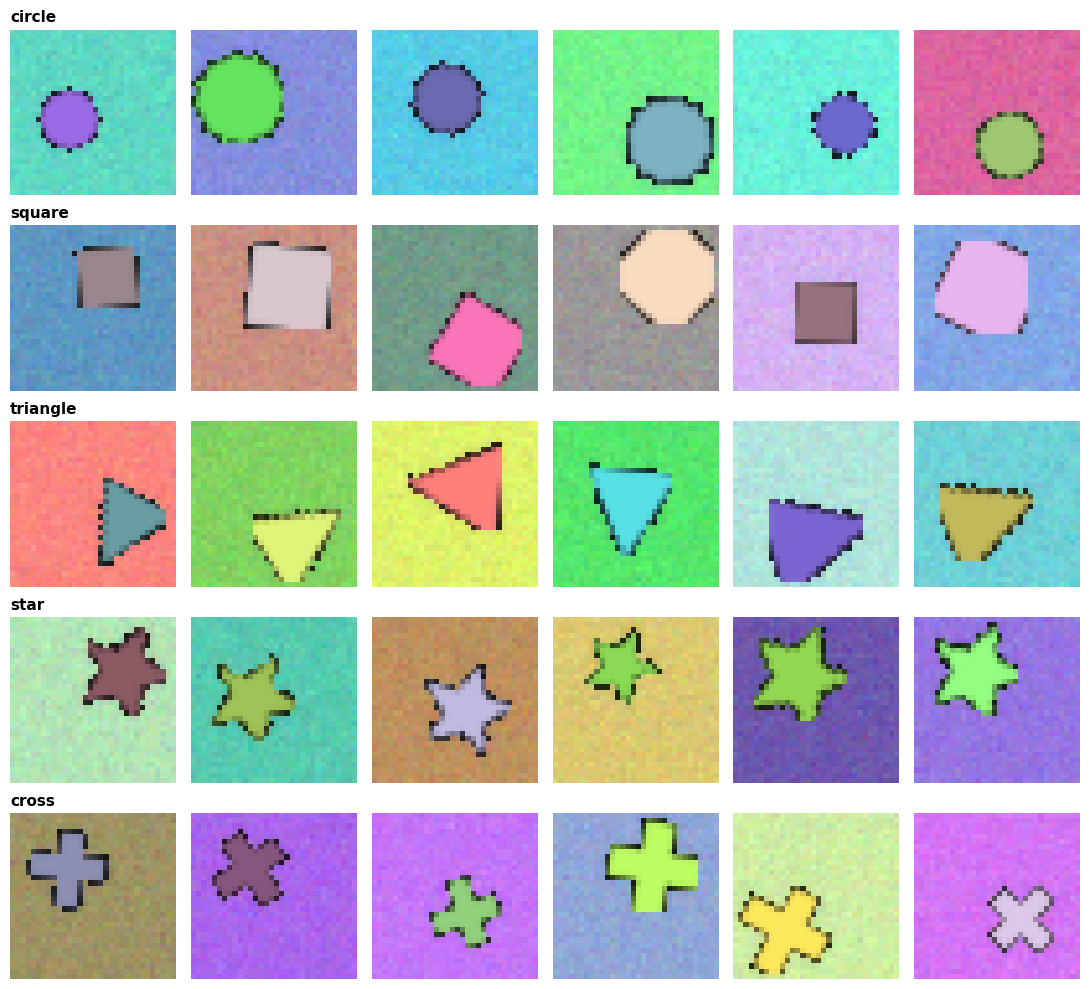

In [6]:
fig, axes = plt.subplots(5, 6, figsize=(11, 10))

for row, shape in enumerate(CLASSES):
    class_indices = np.where(y_labels == row)[0]
    sample_indices = class_indices[:6]
    for col, idx in enumerate(sample_indices):
        axes[row, col].imshow(X_images[idx])
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(shape, loc="left", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

### Line-by-Line Breakdown

- **`np.where(y_labels == row)[0]`** - `np.where(condition)` finds every position in `y_labels` where the condition is `True`. `y_labels == row` checks "does this label match the current class number?" The `[0]` extracts just the list of matching positions (NumPy's `where` technically returns extra structure we don't need here).
- **`class_indices[:6]`** - Takes just the first 6 matching image positions, so we display a small, manageable sample rather than all 400.
- **The nested loop and `imshow`** - Same displaying pattern we've used since Week 6, just now looping over specific shape classes.

Look at the result: unlike yesterday's neatly centred digits, these shapes appear at different positions, sizes, rotations, and colours every time - genuinely closer to a real-world image classification challenge.

# Part 2 - Preparing the Data for Training

Same core steps as every previous week: normalize, then split into training and testing sets.

In [7]:
from sklearn.model_selection import train_test_split

X_normalized = X_images.astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (1600, 32, 32, 3)
Testing images: (400, 32, 32, 3)


### Line-by-Line Breakdown

- **`X_images.astype("float32") / 255.0`** - Our pixel values currently range from 0 to 255 (standard 8-bit colour). Dividing by `255.0` rescales everything into the familiar 0-to-1 range (the same normalization idea from every earlier week, just with `255` instead of `16` since we're using standard colour images now, not the digits dataset's smaller 0-16 range).
- **`train_test_split(..., stratify=y_labels)`** - Exactly the same splitting tool and `stratify` safeguard from every previous week, ensuring all 5 shapes are proportionally represented in both the training and test sets.
- Notice we do **not** need to `.reshape()` anything here, unlike yesterday - `make_image()` already built our images directly in the `(height, width, channels)` shape that `Conv2D` expects.

# Part 3 - An ANN Baseline (For Fair Comparison)

Before building a CNN, let's train the exact same kind of plain ANN from Week 6 Day 2 on this harder dataset, so we have a fair, real baseline to compare against - not just an assumption about how it "should" perform.

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

ann_model = Sequential([
    Input(shape=(32, 32, 3)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

ann_history = ann_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

ann_test_loss, ann_test_accuracy = ann_model.evaluate(X_test, y_test, verbose=0)
print("ANN Test Accuracy:", round(ann_test_accuracy, 4))

I0000 00:00:1788823356.624919     556 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788823356.625447     556 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1788823356.670941     556 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788823357.805121     556 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788823357.805552     556 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1788823357.972124     556 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


ANN Test Accuracy: 0.2


### Line-by-Line Breakdown

- **`Input(shape=(32, 32, 3))`** - Our images are now `32x32` with `3` colour channels, instead of yesterday's `8x8x1`.
- **`Flatten()`** - Immediately unrolls the entire `32 x 32 x 3 = 3,072`-number image into one long line - notice this is far more numbers than yesterday's `64`, purely because the image is bigger and in colour.
- **`Dense(128, activation="relu")`** and **`Dense(64, activation="relu")`** - Two hidden layers, made a bit larger than yesterday's ANN (`128` and `64` neurons instead of `64` and `32`) since this is a bigger, harder input.
- **`Dense(5, activation="softmax")`** - Our output layer now has `5` neurons (one per shape), instead of `10` for digits.
- **The `compile()` and `fit()` calls** - Identical pattern and parameter meanings to Week 6 Day 2 and yesterday: Adam optimizer, `sparse_categorical_crossentropy` loss (multi-class, integer labels), 30 epochs, batch size 32, with 20% of training data held back for validation.
- **`ann_model.evaluate(X_test, y_test, verbose=0)`** - Reports loss and accuracy on the untouched test set, exactly as before.

### Observation

Keep this ANN's test accuracy in mind - we'll compare it directly against our CNN in Part 5. Because shapes in this dataset can appear **anywhere** in the image, a `Dense` layer (which learns a *fixed* weight for every one of the 3,072 flattened pixel positions) has a much harder time: a weight that's useful when a circle happens to sit in the top-left corner isn't automatically useful when that same circle appears in the bottom-right corner instead.

# Part 4 - Building a Deeper CNN for a Harder Task

Since today's images are more complex than yesterday's, we'll use **three** Conv+Pool blocks instead of two, giving the network more chances to build up from simple edges to full shape outlines.

In [9]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

cnn_model = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,509 (349.64 KB)

 Trainable params: 89,509 (349.64 KB)

 Non-trainable params: 0 (0.00 B)

### Line-by-Line Breakdown

- **`Conv2D(16, ...)` -> `MaxPooling2D(...)`** - Block 1: 16 filters scan the raw 32x32 image looking for the simplest patterns (edges, basic colour boundaries), then pooling shrinks the result to 16x16.
- **`Conv2D(32, ...)` -> `MaxPooling2D(...)`** - Block 2: 32 filters now scan the *already-simplified* 16x16 feature maps from Block 1, combining simple edges into more complex shapes (corners, curves). Pooling shrinks this to 8x8.
- **`Conv2D(64, ...)` -> `MaxPooling2D(...)`** - Block 3: 64 filters look for even higher-level patterns within Block 2's output (nearly-complete shape outlines). Pooling shrinks this down to 4x4.
- **Why the filter counts grow (16 → 32 → 64)?** Early layers only need a few filters to capture simple patterns like edges, but later layers need many more filters to capture the much larger variety of complex shape-combinations built from those simple patterns.
- **`Flatten()` -> `Dense(64, activation="relu")` -> `Dense(5, activation="softmax")`** - Exactly the same classification head pattern as yesterday, just with `5` output neurons instead of `10`.

In [10]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_history = cnn_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(X_test, y_test, verbose=0)
print("CNN Test Accuracy:", round(cnn_test_accuracy, 4))

CNN Test Accuracy: 0.835


### Line-by-Line Breakdown

Identical structure to the ANN's `compile()`/`fit()`/`evaluate()` calls in Part 3 - same optimizer, same loss function, same number of epochs and batch size, so that any difference we see in the results comes from the *architecture*, not from unfair training settings.

## Visualize CNN Training

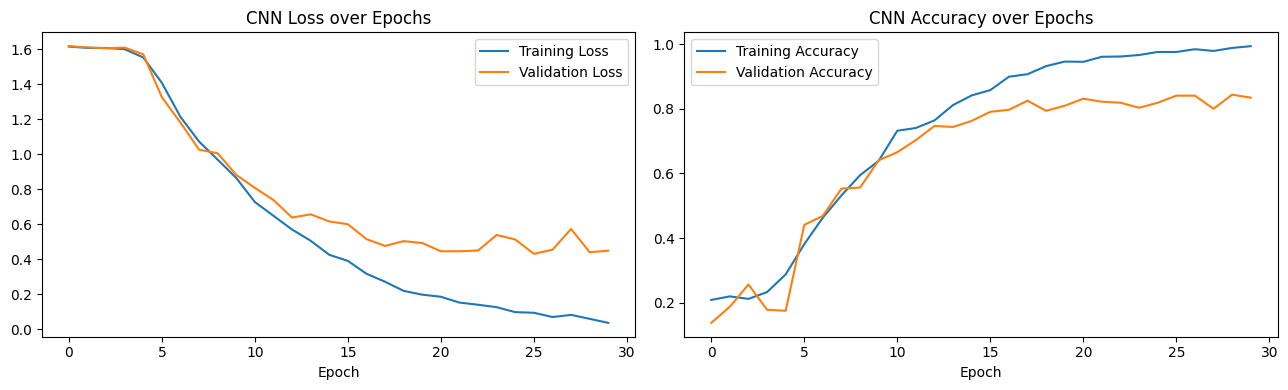

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(cnn_history.history["loss"], label="Training Loss")
axes[0].plot(cnn_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("CNN Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(cnn_history.history["accuracy"], label="Training Accuracy")
axes[1].plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("CNN Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

Same chart-reading rules from Week 6 Day 2 and yesterday apply here: if training accuracy keeps climbing while validation accuracy stalls or drops, that's overfitting.

# Part 5 - ANN vs CNN: The Real, Honest Comparison

Let's put the actual numbers side by side.

In [12]:
comparison_table = pd.DataFrame({
    "Model": ["ANN (Part 3)", "CNN (Part 4)"],
    "Parameters": [ann_model.count_params(), cnn_model.count_params()],
    "Test Accuracy": [round(ann_test_accuracy, 4), round(cnn_test_accuracy, 4)],
})
comparison_table

,Model,Parameters,Test Accuracy
0,ANN (Part 3),401925,0.200
1,CNN (Part 4),89509,0.835


### Line-by-Line Breakdown

- **`ann_model.count_params()`** and **`cnn_model.count_params()`** - Keras models track how many individual learnable numbers (weights and biases) they contain in total. We include this so we can see not just *which* model performed better, but *how efficiently* it did so.
- **The rest** builds and displays a small comparison table, exactly the same `pd.DataFrame({...})` pattern from yesterday's Part 9.

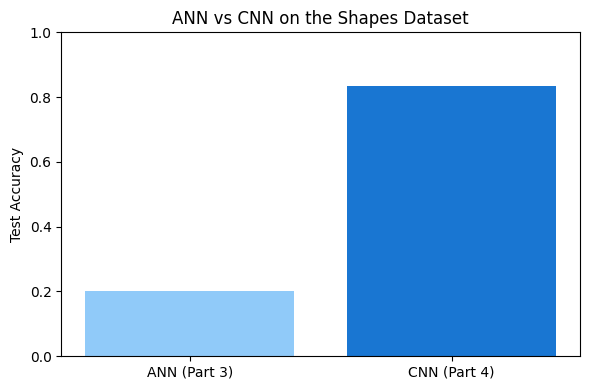

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(comparison_table["Model"], comparison_table["Test Accuracy"], color=["#90caf9", "#1976d2"])
ax.set_ylabel("Test Accuracy")
ax.set_title("ANN vs CNN on the Shapes Dataset")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### Interpreting the Result Honestly

Look at the real numbers from Part 3 and Part 4: the ANN landed at about **20% test accuracy** - which, with 5 balanced classes, is exactly what you'd get from **pure random guessing**. The CNN reached about **83.5%**.

This is a striking result, and it makes complete sense once we remember how this dataset was built: every shape appears at a genuinely random position, size, and rotation. A `Dense` layer assigns one fixed weight to each of the 3,072 flattened pixel positions - it has no way to say "I'm looking for a circle-shaped pattern, wherever it happens to be." Whatever it learned about a circle sitting in the top-left corner is completely useless when that same circle appears in the bottom-right corner instead, so with shapes scattered randomly across the whole canvas, the ANN essentially had no consistent signal to learn from at all.

A CNN's filters, by contrast, slide across the *entire* image looking for the same pattern everywhere - so a circle is a circle to a CNN's filter, regardless of where it sits. That is precisely why the CNN could actually learn this task while the ANN could not.

# Part 6 - Data Augmentation

Even with 2,000 images, our CNN has only ever seen a limited set of rotations, positions, and sizes for each shape. **Data augmentation** creates realistic variations of our training images *on the fly*, during training, without us needing to generate and store even more raw images.

### The Idea, in Plain Language

Imagine showing a student many slightly different versions of the same practice question - flipped left-right, slightly rotated, zoomed in a little - to help them learn the *underlying concept* rather than memorising one specific version. Data augmentation does exactly this for a Neural Network: during training, it randomly tweaks each image a little before the network sees it, so the network is forced to learn features that survive small, realistic changes.

In [14]:
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.15),
    RandomZoom(0.15),
    RandomTranslation(0.1, 0.1),
])

### Line-by-Line Breakdown

- **`RandomFlip("horizontal")`** - Randomly mirrors an image left-to-right (like looking at it in a mirror) about 50% of the time during training.
- **`RandomRotation(0.15)`** - Randomly rotates the image by up to `0.15 * 360 = 54` degrees in either direction.
- **`RandomZoom(0.15)`** - Randomly zooms in or out by up to 15%.
- **`RandomTranslation(0.1, 0.1)`** - Randomly shifts the image up/down and left/right by up to 10% of its size.
- **Wrapping all four in a `Sequential([...])`** - Chains them together into a single mini-pipeline: every image that passes through will be flipped, then rotated, then zoomed, then shifted, each with independently random settings.

**Important:** these augmentation layers are only ever active **during training**. When we later call `.evaluate()` or `.predict()`, Keras automatically switches them off, so our test set is always judged on the real, unmodified images.

In [15]:
augmented_cnn_model = Sequential([
    Input(shape=(32, 32, 3)),
    data_augmentation,

    Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(5, activation="softmax")
])

augmented_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmented_history = augmented_cnn_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

augmented_test_loss, augmented_test_accuracy = augmented_cnn_model.evaluate(X_test, y_test, verbose=0)
print("CNN with Augmentation - Test Accuracy:", round(augmented_test_accuracy, 4))

CNN with Augmentation - Test Accuracy: 0.6075


### Line-by-Line Breakdown

- **`data_augmentation` placed right after `Input(...)`** - This is the *only* architectural change from Part 4's CNN. Every image entering the network during training now passes through our augmentation pipeline first, then continues through the exact same `Conv2D`/`MaxPooling2D`/`Dense` layers as before.
- **Everything else** - identical architecture, identical `compile()` and `fit()` settings to Part 4's CNN, so the comparison is fair.

In [16]:
augmentation_comparison = pd.DataFrame({
    "Model": ["CNN (no augmentation)", "CNN (with augmentation)"],
    "Test Accuracy": [round(cnn_test_accuracy, 4), round(augmented_test_accuracy, 4)],
})
augmentation_comparison

,Model,Test Accuracy
0,CNN (no augmentation),0.8350
1,CNN (with augmentation),0.6075


### Interpreting the Result Honestly

Look at the real numbers: the CNN without augmentation reached about **83.5%**, while the CNN *with* augmentation only reached about **60.75%** - augmentation made things noticeably **worse** here, not better.

This is a genuinely useful result to sit with, rather than a fluke to ignore. A likely explanation: our shapes dataset **already** contains heavy random variation (position, rotation, size) baked into every single image from Part 1. Stacking *even more* random flips, rotations, zooms, and shifts on top of that already-hard task made the effective training problem considerably harder, without giving the network any more epochs to compensate - so, within the same 30 epochs, it simply didn't have enough time to converge as well as the un-augmented version did.

**The lesson:** augmentation is not automatically "free extra performance." It helps most when your original dataset is small or lacks variation your real-world test data will contain. When your dataset (like ours) already includes plenty of built-in variation, piling on strong augmentation can overload training instead of helping it - which is exactly why we test and measure, rather than assume.

# Mini Practical Activity

1. Change `IMAGES_PER_CLASS` from `400` to `100` and regenerate the dataset. Does the gap between the ANN and CNN change? Does augmentation help more or less with less data?
2. Remove `RandomRotation` from the augmentation pipeline (keep the others) and retrain. Does accuracy change?
3. Add a 4th shape class of your own design (e.g. a diamond, using `fillPoly` with 4 points) to `draw_shape_patch` and `CLASSES`, regenerate the dataset, and retrain both models.

### Exercise 1

Look at a few misclassified test images (compare `y_test` against each model's predictions). Are the CNN's mistakes different in kind from the ANN's mistakes? What do the ANN's mistakes tend to have in common?

### Exercise 2

In your own words, explain why `RandomFlip`, `RandomRotation`, `RandomZoom`, and `RandomTranslation` are only active during training, and what would go wrong if they stayed active during evaluation too.

### Exercise 3

Using `comparison_table` from Part 5, write 2-3 sentences connecting the *size* of the accuracy gap you found to how this dataset was deliberately designed (random position, rotation, size) compared to yesterday's centred, fixed-size digits.

# Lesson Summary

Today, you learned how to:

- Build a bigger, more realistic synthetic image dataset with OpenCV, understanding every randomisation step.
- Prepare a colour (RGB) dataset for training.
- Train and evaluate an ANN baseline on a genuinely harder image task.
- Build a deeper, 3-block CNN suited to more complex images.
- Compare an ANN and CNN fairly, and interpret real results rather than assuming an outcome.
- Explain and implement data augmentation using Keras's built-in augmentation layers.
- Evaluate honestly whether augmentation helped, in this specific case.

# Functions and Concepts Learned Today

| Item | Purpose |
|---|---|
| `cv2.fillPoly()` | Fills in any shape described by a list of corner points |
| `cv2.getRotationMatrix2D()` / `cv2.warpAffine()` | Rotates and scales an image or patch |
| Boolean mask (`shape_mask`) | Marks exactly which pixels belong to the shape, for clean pasting |
| `np.random.default_rng(seed)` | Creates a reproducible random number generator |
| RGB image | A colour image with 3 channels (Red, Green, Blue), instead of 1 grayscale channel |
| `model.count_params()` | Reports how many learnable numbers a Keras model contains |
| Deeper CNN (3 Conv+Pool blocks) | More blocks let a network build from simple to complex patterns |
| Data Augmentation | Randomly modifies training images on the fly to improve generalisation |
| `RandomFlip` / `RandomRotation` / `RandomZoom` / `RandomTranslation` | Keras layers implementing common augmentations |
| Augmentation layers inside `Sequential` | Only active during training; automatically switched off during evaluation/prediction |

# Key Takeaways

✅ A harder, more realistic dataset (random position, size, rotation) reveals a CNN's real advantage over a plain ANN far more clearly than an easy, centred dataset does.

✅ Deeper CNNs (more Conv+Pool blocks) let a network build up from simple patterns (edges) to complex ones (whole shapes).

✅ Data augmentation randomly varies training images on the fly, and is only active during training - never during evaluation or prediction.

✅ Augmentation is a tool to test and measure, not something to assume automatically helps - its benefit depends on how much variation your original dataset already contains.

✅ Always compare models using real, measured results - not assumptions about which "should" win.

# Assignment

Submit a Jupyter Notebook with:

1. A brief description of the dataset used (or your own modified version, if you completed the Mini Practical Activity).
2. An ANN baseline, trained and evaluated, with its test accuracy reported.
3. A CNN with at least 2 Conv+Pool blocks, trained and evaluated, with its test accuracy reported.
4. A clear comparison (table or chart) of the ANN vs CNN results, with a written paragraph explaining the result you actually observed.
5. At least one data augmentation experiment, with a before/after test accuracy comparison.
6. A short reflection: did augmentation help in your case? Why do you think that happened?

# Final Reflection

1. In your own words, why does a CNN typically outperform an ANN more clearly on this shapes dataset than on yesterday's centred digits?
2. What does `shape_mask` do in our `make_image()` function, and why was it necessary?
3. Why did we grow the number of filters across Conv2D layers (16 → 32 → 64) instead of keeping them the same?
4. What is data augmentation, in your own words?
5. Why must augmentation layers be switched off automatically during evaluation?
6. Based on your own results, did data augmentation help, hurt, or make no meaningful difference for this dataset? What's your best explanation for that outcome?
7. If you doubled `IMAGES_PER_CLASS`, would you expect the ANN-vs-CNN gap to grow, shrink, or stay about the same? Why?

# Preview: Week 8 - Natural Language Processing (NLP)

Next week, we leave images behind and turn to **text** - tokenization, cleaning text data, and building our first sentiment classifier. Many of today's ideas carry over in spirit: just as a CNN needs to handle a shape appearing *anywhere* in an image, an NLP model needs to handle a word's meaning changing depending on *where* it appears in a sentence.